# Credit Policy Scenario Analysis

This notebook evaluates how different **PD (probability of default) thresholds** affect the credit approval policy.

For each threshold, a customer is **approved** if the model's predicted PD is **less than or equal to** the threshold, and **rejected** otherwise. We then compute metrics that show the trade-off between approving more customers and taking on more risk.

**Steps:**
1. Import libraries and project functions
2. Define the analysis parameters
3. Load the validation data
4. Process the data and generate model predictions
5. Compute metrics for each threshold
6. Visualize the trade-off
7. Save the results


In [4]:
# Automatically reload modules from src/ when their code changes,
# without restarting the kernel.
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from src.config import X_VAL_DIR, Y_VAL_DIR, MODELS_CALIBRATED, CREDIT_POLICY_DIR
from src.processing import process_data
from src.scenario_analysis import scenario_analysis  # adjust to the module where the function lives

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Analysis parameters

Change the values below to test other scenarios:

- `THRESHOLDS`: PD thresholds to evaluate. A **lower** threshold makes the policy more **conservative** (fewer approvals, lower risk).
- `MODEL_NAME`: which calibrated model to use. It must be one of the keys of `MODELS_CALIBRATED` in `src/config.py`.
- `SAVE_RESULTS`: if `True`, saves the final table to a CSV file.

In [5]:
THRESHOLDS = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
MODEL_NAME = "lightgbm"
SAVE_RESULTS = True

print("Available models:", list(MODELS_CALIBRATED.keys()))

Available models: ['log_reg', 'random_forest', 'catboost', 'xgboost', 'lightgbm']


## 2. Load the validation data

We use the **validation** set, not the training set, so the metrics reflect the model's performance on data it has not seen.

- `X_val`: explanatory variables (features) for each customer.
- `y_val`: actual label, where `1` = default and `0` = non-default.

Both are indexed by the `ID` column, which keeps predictions and labels aligned.

In [6]:
X_val = pd.read_csv(X_VAL_DIR, index_col="ID")
y_val = pd.read_csv(Y_VAL_DIR, index_col="ID").squeeze("columns")

print(f"X_val: {X_val.shape[0]} rows x {X_val.shape[1]} columns")
print(f"y_val: {y_val.shape[0]} rows | default rate: {y_val.mean():.2%}")

# Make sure X and y list customers in the same order
assert X_val.index.equals(y_val.index), "X_val and y_val indexes do not match!"

X_val: 22500 rows x 10 columns
y_val: 22500 rows | default rate: 6.68%


## 3. Process the data and generate predictions

1. `process_data` applies the transformations the model expects, the same ones used during training.
2. The calibrated model is loaded from disk.
3. `predict_proba(...)[:, 1]` returns each customer's **probability of default**. Column 1 corresponds to class `1` (default).

Because the model is **calibrated**, these probabilities can be read directly as PDs. That is why it makes sense to compare them with thresholds such as 5% or 10%.

In [8]:
model_config = MODELS_CALIBRATED[MODEL_NAME]

X_val_processed = process_data(model=model_config["type"], X=X_val)

model = joblib.load(model_config["path"])
y_pred = model.predict_proba(X_val_processed)[:, 1]

print(f"Model: {MODEL_NAME} ({model_config['path']})")
print(f"Predicted PD: mean {y_pred.mean():.2%} | min {y_pred.min():.2%} | max {y_pred.max():.2%}")

Model: lightgbm (/Users/hamiltondealmeidanascimento/Credit-Risk-Modeling/calibration/calibrated_model_LightGBM.joblib)
Predicted PD: mean 6.68% | min 0.07% | max 82.81%


## 4. Scenario analysis

For each threshold, `scenario_analysis` computes:

| Metric | Meaning |
|---|---|
| `acceptance_rate` | % of customers approved |
| `rejection_rate` | % of customers rejected |
| `approved_mean_pd` | Mean predicted PD among approved customers (expected portfolio risk) |
| `default_approved_rate` | % of **actual** defaults among approved customers (realized risk) |
| `default_rejected_rate` | % of actual defaults among rejected customers |
| `default_captured_rate` | % of all defaults the policy managed to block |
| `non_default_rejected_rate` | % of good payers who were rejected (opportunity cost) |

**How to read it:** the ideal policy has a **high** `default_captured_rate` and a **low** `non_default_rejected_rate`. Raising the threshold increases approvals, but also increases portfolio risk.

If `approved_mean_pd` is close to `default_approved_rate`, the model is well calibrated.


In [9]:
metrics_df = pd.DataFrame(
    [scenario_analysis(y_prob=y_pred, y=y_val, lim=t) for t in THRESHOLDS]
)

metrics_df

,threshold,acceptance_rate,rejection_rate,approved_mean_pd,default_approved_rate,default_rejected_rate,default_captured_rate,non_default_rejected_rate
0,0.05,0.6966,0.3034,0.0154,0.0152,0.1854,0.8418,0.2649
1,0.10,0.8300,0.1700,0.0245,0.0243,0.2748,0.6988,0.1321
2,0.15,0.8839,0.1161,0.0304,0.0299,0.3484,0.6051,0.0811
3,0.20,0.9094,0.0906,0.0344,0.0342,0.3948,0.5352,0.0588
4,0.30,0.9395,0.0605,0.0412,0.0405,0.4754,0.4302,0.0340
5,0.40,0.9617,0.0383,0.0483,0.0479,0.5424,0.3105,0.0188
6,0.50,0.9782,0.0218,0.0550,0.0554,0.5804,0.1895,0.0098


## 5. Trade-off visualization

The left chart shows **approval vs. risk of the approved portfolio**. The right chart shows **defaults blocked vs. good customers lost**.

Use it to choose a threshold: look for the point where gaining more approvals starts to cost too much risk.

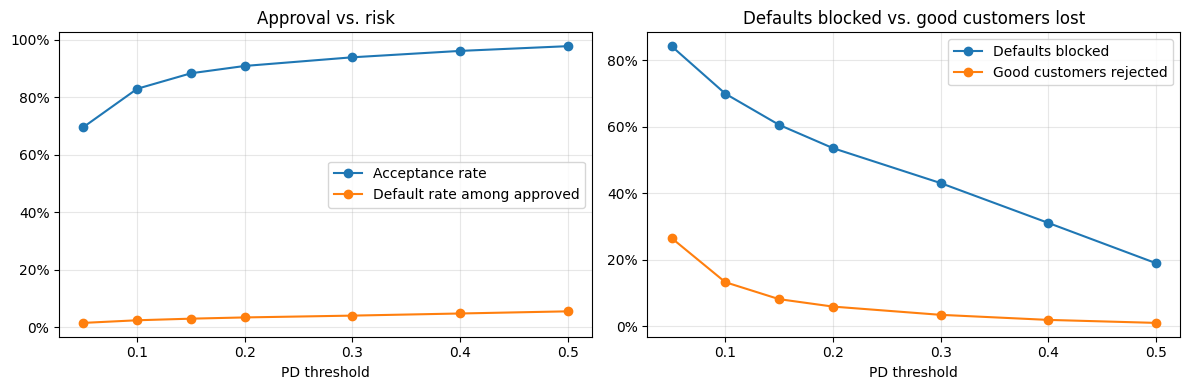

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(metrics_df["threshold"], metrics_df["acceptance_rate"], marker="o", label="Acceptance rate")
axes[0].plot(metrics_df["threshold"], metrics_df["default_approved_rate"], marker="o", label="Default rate among approved")
axes[0].set_title("Approval vs. risk")

axes[1].plot(metrics_df["threshold"], metrics_df["default_captured_rate"], marker="o", label="Defaults blocked")
axes[1].plot(metrics_df["threshold"], metrics_df["non_default_rejected_rate"], marker="o", label="Good customers rejected")
axes[1].set_title("Defaults blocked vs. good customers lost")

for ax in axes:
    ax.set_xlabel("PD threshold")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## 6. Save the results

The table is saved to `CREDIT_POLICY_DIR/policy_comparison.csv`. The folder is created if it does not exist.

To avoid overwriting the file, set `SAVE_RESULTS` to `False` in the parameters section.

In [11]:
if SAVE_RESULTS:
    CREDIT_POLICY_DIR.mkdir(parents=True, exist_ok=True)
    output_path = CREDIT_POLICY_DIR / "policy_comparison.csv"
    metrics_df.to_csv(output_path, index=False)
    print(f"Results saved to: {output_path}")

Results saved to: /Users/hamiltondealmeidanascimento/Credit-Risk-Modeling/reports/credit_policy/policy_comparison.csv


## 7. Threshold impact on the credit policy

### Overview

The overall default rate in the validation set is about **6.7%**. Every threshold reduces the default rate of the approved portfolio below that level, but the cost of the reduction, measured in good customers turned away, varies a lot across thresholds.

| Threshold | Acceptance | Default among approved | Defaults blocked | Good customers rejected |
|---|---|---|---|---|
| 5% | 69.7% | 1.52% | 84.2% | 26.5% |
| 10% | 83.0% | 2.43% | 69.9% | 13.2% |
| 15% | 88.4% | 2.99% | 60.5% | 8.1% |
| 20% | 90.9% | 3.42% | 53.5% | 5.9% |
| 30% | 94.0% | 4.05% | 43.0% | 3.4% |
| 40% | 96.2% | 4.79% | 31.1% | 1.9% |
| 50% | 97.8% | 5.54% | 19.0% | 1.0% |

### Key findings

**1. Most of the model's value is concentrated in the lowest PD thresholds.** Most customers have a low predicted PD: a 10% threshold already approves 83% of applicants while cutting the default rate of the approved portfolio from 6.7% to 2.4% (about 64% lower) and blocking 70% of all defaults.

**2. Very conservative thresholds are expensive.** Moving from 10% to 5% blocks an extra 14 p.p. of defaults, but rejects an extra 13 p.p. of good payers and lowers approval to under 70%. At 5%, more than one in four good customers is turned away.

**3. Very permissive thresholds make the model almost irrelevant.** At 50%, the policy approves 97.8% of applicants, blocks only 19% of defaults, and the approved portfolio's default rate (5.5%) is close to the overall rate (6.7%).

**4. The model is very well calibrated.** The expected risk (`approved_mean_pd`) and the realized risk (`default_approved_rate`) differ by less than 0.1 p.p. at every threshold, e.g., 2.45% vs. 2.43% at the 10% threshold. This means predicted PDs can be read as real probabilities, and thresholds can be set directly from business targets.

### Marginal analysis

The table below shows the default rate **only among the customers added** when the threshold is raised to the next level. For example, the 13.3% of applicants approved when moving from 5% to 10% default at about 7.2%.

| PD band | Additional approvals | Default rate of added customers | Good customers per default in the band |
|---|---|---|---|
| 5% → 10% | +13.3 p.p. | ~7.2% | ~12.9 |
| 10% → 15% | +5.4 p.p. | ~11.6% | ~7.6 |
| 15% → 20% | +2.6 p.p. | ~18.3% | ~4.5 |
| 20% → 30% | +3.0 p.p. | ~23.1% | ~3.3 |
| 30% → 40% | +2.2 p.p. | ~36.1% | ~1.8 |
| 40% → 50% | +1.7 p.p. | ~49.3% | ~1.0 |

*Values derived from the rounded metrics above, so they are approximate.*

Each band's default rate falls inside its PD range, which further confirms the calibration. The last column shows the trade-off clearly: rejecting the 5%–10% band avoids one default for every ~13 good customers lost, while rejecting the 40%–50% band avoids one default for every good customer lost.

### Recommendation

From a risk-return perspective, the **10%–15% range** looks like the best balance: approval of 83%–88%, a portfolio default rate of 2.4%–3.0% (less than half the overall rate), 60%–70% of defaults blocked, and only 8%–13% of good customers rejected.

Because the model is well calibrated, the threshold can be chosen precisely once unit economics are known. Approving a customer is profitable when their PD is below the **break-even PD**:

$$
PD^{*} = \frac{\text{profit per good customer}}{\text{profit per good customer} + \text{loss per default}}
$$

For example (hypothetical numbers), if a good customer yields a 10% margin on the exposure and a default loses 60% of it (LGD), then PD* = 0.10 / (0.10 + 0.60) ≈ 14%, which falls within the recommended range.

### Limitations

- Results are based on the **validation set**. The chosen threshold should be confirmed on the **test set** or on out-of-time data before adoption.
- The training data may include only previously approved customers (**reject inference** problem), which can bias estimates for applicants who would have been rejected in the past.
- The analysis uses rates, not monetary values. A profit-based analysis using real margins, LGD and exposure would give a more direct basis for the final decision.